In [1]:
import geopandas as gpd
import pandas as pd
import geodatasets
import json
from pathlib import Path
import matplotlib.pyplot as plt
import contextily as cx
from shapely.geometry import box, shape
import string
from geopy.geocoders import Nominatim
from geopy.location import Location


In [233]:
locations = geolocator.geocode("Flatford Mill, Suffolk", exactly_one=False)
len(locations)
l:Location = locations[0]
locations

[Location(Flatford Mill, Flatford Lane, Flatford, East Bergholt, Babergh, Suffolk, England, CO7 6UL, United Kingdom, (51.958828, 1.021697, 0.0))]

In [192]:
candidate_names_not_found

{'PLEASE STOP THE PYLONS',
 'Site Visit Guidance Document',
 'Simon Neesam',
 'Hinkley Point C',
 'APP022F',
 'Green Book',
 'UG',
 'NWL&#39',
 'Viability Impact',
 'National Grid Design Development Report',
 'Nicki Lyden',
 'Gliding Club',
 'Leading Planning Barrister',
 'Cable Sealing End Compound Site',
 'EC5N',
 'Special Area',
 'AldhamCarpentry',
 'Mike Kent Honey',
 'RG079',
 'Companies House',
 'Unacceptable Construction Disruption',
 'Spanish Armada',
 'Consider Reasonable Alternatives',
 'Emma L Harrold',
 'Citizen&#39',
 'Industrial-scale',
 'Great Grid Upgrade',
 'U S',
 'TB89',
 'UKPN Undergrounding',
 'Rivers Wid',
 'Alison Ellis',
 'Brack',
 'Maltby',
 'Stickfer',
 'Welfare Services',
 'THE OFFSHORE ROUTE IS',
 'Black Worcester',
 'PLanning Inspector',
 'Darren',
 'Chignalls&#39',
 'Free&#39',
 'Lopez Ostra',
 'RG136',
 'Arnhem',
 'THIS IS WHAT WAS DECIDED FOR YOU',
 'Land Drainage Act',
 'With Fordham',
 'Local Development Scheme',
 'Pipeline Safety Regulations',
 'Essex

In [2]:
with open("sanitised_candidate_places.json", "r") as f:
    candidate_places_dict = json.load(f)
candidate_places_dict

{'100008573': ['Thames'],
 '100008574': ['NIMBYS',
  'D',
  'Funnell',
  'NIMBYs',
  'Milliband MP',
  'Millband',
  'C',
  'UK'],
 '100008577': ['National Grid'],
 '100008579': ['MPs',
  'AONB',
  'HDVC',
  'Dedham',
  'Tendring',
  'London',
  'Ardleigh',
  'National Grid'],
 '100008581': ['Targeted Consultation',
  'Pylon Campaign',
  'A12',
  'Interconnector',
  'Ardleigh',
  'North Falls',
  'FP',
  'Tarcon Interconnector',
  'Five Estuaries',
  'Tendring',
  'From April',
  'TB009',
  'Cumulative Effects',
  'Home Farm Lane',
  'April',
  'National Grid Image A16',
  'September',
  'Link PAR31',
  'TB004',
  'Ardleigh Road',
  'Garden Community',
  'Home Farm Land',
  'Ardleigh Parish Council',
  'National Grid&#39',
  'No&#39',
  'A137',
  'Little Bromley Road',
  'National Grid'],
 '100008583': ['HVDC'],
 '100008584': ['National Grid', 'East Anglia', 'Miliband&#39', 'Pylons Group'],
 '100008586': ['HVDC'],
 '100008590': ['PS', 'Anglia Impact', 'NIMBY'],
 '100008592': ['Billeric

In [9]:
sorted(candidate_places_dict['100013049']) # good example

['A140',
 'A4 Environmental Statement Appendix',
 'AC',
 'B1113',
 'Babergh Councils',
 'Back Street',
 'Burgate Rd',
 'Church Farmhouse',
 'Dedham Vale',
 'Design Development Report Appendices',
 'Domesday Book',
 'EN020027-000279-2',
 'ESO',
 'ESO East Anglia Study',
 'East Anglia',
 'England',
 'FP267',
 'Finningham Road',
 'Fri',
 'Gislingham',
 'Grade II',
 'Great Crested Newt',
 'Green Party MP',
 'Grey Partridge',
 'HDVC',
 'HGV',
 'HVDC',
 'Hartismere High School',
 'Hazel Dormouse',
 'Hidcote House',
 'Historic Environment Paragraphs',
 'Ivy House Farm',
 'Jan',
 'London',
 'MSF15878',
 'Mellis',
 'Mellis Road',
 'Mill Street',
 'N2T',
 'NG',
 'NG Baseline Assessment',
 'NG Design Development Report',
 'NIMBYism',
 'NPPF',
 'NPS EN-1 Par',
 'National Grid',
 'National Heritage List',
 'Near RG118',
 'Net Zero',
 'Nov',
 'Oct',
 'Old Guildhall',
 'Plateau Claylands',
 'Public Rights',
 'RG108-RG116',
 'RG113',
 'RG114',
 'RG116',
 'RG117',
 'RG117-119',
 'RG117-RG124',
 'RG118'

In [3]:
unique_candidate_names = set()
sanitised_candidate_places = {}

def tidy(placenm):
    if placenm and placenm[-1] in string.punctuation:
        return placenm[:-1].replace("!", "").replace("?", "").strip()
    return placenm.replace("!", "").replace("?", "").strip()

for id, place_list in candidate_places_dict.items():
    # The saved json is now sanitised already.
    # sanitised_place_list = list(set([tidy(s) for s in place_list]))
    # sanitised_candidate_places[id] = sanitised_place_list
    # for placename in sanitised_place_list:
    #     unique_candidate_names.add(placename)

    for placename in place_list:
        unique_candidate_names.add(placename)

len(unique_candidate_names)

# There are 7300 candidate place names.


7300

In [173]:
with open("sanitised_candidate_places.json", "w") as f:
    json.dump(sanitised_candidate_places, f)

<Axes: >

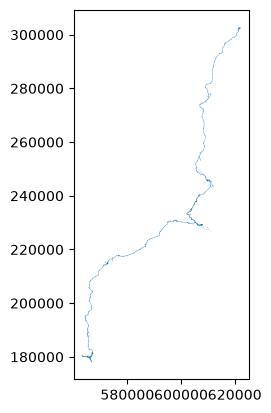

In [4]:
gdf_nt_route = gpd.read_file("../Routes/norwich-tilbury-boundary.geojson").to_crs("epsg:27700")
gdf_nt_route = gdf_nt_route.iloc[[2],:]
gdf_nt_route.plot()

D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_18800\948502922.py:9: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  gdf_buffer["geometry"] = buffer
D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_18800\948502922.py:13: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set

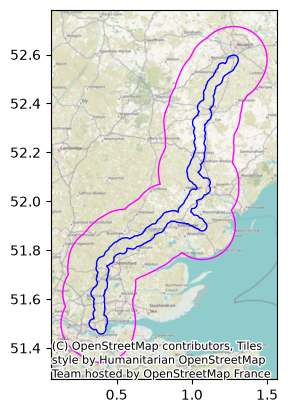

In [5]:
buffer = gdf_nt_route.buffer(15000)
buffer2 = gdf_nt_route.buffer(2000)

# The below is purely to get a look at the buffers.

bbox = box(*buffer.total_bounds)

gdf_buffer = gpd.GeoDataFrame()
gdf_buffer["geometry"] = buffer
gdf_buffer.set_crs("epsg:27700", inplace=True)

gdf_buffer2 = gpd.GeoDataFrame()
gdf_buffer2["geometry"] = buffer2
gdf_buffer2.set_crs("epsg:27700", inplace=True)

gdf_buffer = pd.concat([gdf_buffer, gdf_buffer2], axis = 0)
del gdf_buffer2

fig, ax = plt.subplots()
gdf_buffer.to_crs("epsg:4326").iloc[[0]].plot(ax = ax, edgecolor = 'magenta', color = 'none')
gdf_buffer.to_crs("epsg:4326").iloc[[1]].plot(ax = ax, edgecolor = 'blue', color = 'none')
cx.add_basemap(ax = ax, crs = "epsg:4326", zoom = 9)



(193408, 33)
(122145, 33)
(13648, 33)


<Axes: >

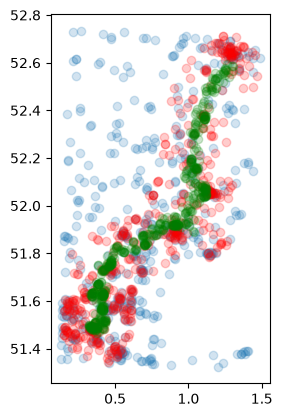

In [6]:
bbox_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    bbox=bbox,
    # mask = buffer,
)
print(bbox_placenames.shape)

buffer1_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer,
)
print(buffer1_placenames.shape)

buffer2_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer2,
)
print(buffer2_placenames.shape)

fig, ax = plt.subplots()
bbox_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2)
buffer1_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'red')
buffer2_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'green')



In [10]:
bbox_placenames["name1_lower"] = bbox_placenames["name1"].map(lambda s:s.lower())
buffer1_placenames["name1_lower"] = buffer1_placenames["name1"].map(lambda s:s.lower())
buffer2_placenames["name1_lower"] = buffer2_placenames["name1"].map(lambda s:s.lower())
bbox_placenames.sample(100)

,id,names_uri,name1,name1_lang,name2,name2_lang,type,local_type,most_detail_view_res,least_detail_view_res,...,county_unitary_type,region,region_uri,country,country_uri,related_spatial_object,same_as_dbpedia,same_as_geonames,geometry,name1_lower
109786,CB63LD,http://data.ordnancesurvey.co.uk/id/postcodeun...,CB6 3LD,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (551231 274575),cb6 3ld
101052,IP117NZ,http://data.ordnancesurvey.co.uk/id/postcodeun...,IP11 7NZ,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (630094 234470),ip11 7nz
115621,PE339SL,http://data.ordnancesurvey.co.uk/id/postcodeun...,PE33 9SL,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (570217 299827),pe33 9sl
29388,RM126FQ,http://data.ordnancesurvey.co.uk/id/postcodeun...,RM12 6FQ,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,London,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (553933 185562),rm12 6fq
130060,osgb4000000027464400,http://data.ordnancesurvey.co.uk/id/4000000027...,New Lane,None,None,None,transportNetwork,Named Road,4000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (605722 310833),new lane
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134198,osgb4000000074706380,http://data.ordnancesurvey.co.uk/id/4000000074...,Big Wood,None,None,None,landcover,Woodland Or Forest,5000,400000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (581548 292133),big wood
69394,osgb4000000028045991,http://data.ordnancesurvey.co.uk/id/4000000028...,Westfield Drive,None,None,None,transportNetwork,Named Road,1000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (585060 223307),westfield drive
175730,CO30SE,http://data.ordnancesurvey.co.uk/id/postcodeun...,CO3 0SE,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (595107 225277),co3 0se
35071,osgb4000000074635200,http://data.ordnancesurvey.co.uk/id/4000000074...,Little Palmer's Shaw,None,None,None,landcover,Woodland Or Forest,1000,400000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (560102 181331),little palmer's shaw


In [11]:
candidate_names_not_found = set()
candidate_names_not_found_OS = set()
found_multiple = set()

assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'

gdf_located_places = gpd.GeoDataFrame(columns = ["place_name", "type", "local_type", "postcode_district", "populated_place", "county_unitary", "geometry", "approx_match_flag"])

# def query_nominatim(candidate_name, adjusted_name):
#     locations = (geolocator.geocode(f"{adjusted_name}, Essex", exactly_one=False) or []) + (geolocator.geocode(f"{placename}, Suffolk", exactly_one=False) or []) + (geolocator.geocode(f"{placename}, norfolk", exactly_one=False) or [])
#     returndf = gpd.GeoDataFrame()
#     returndf["geometry"] = gpd.points_from_xy([loc.longitude for loc in locations],[loc.latitude for loc in locations])
#     returndf["place_name"] = candidate_name
#     returndf["type"] = None
#     returndf["local_type"] = None
#     returndf["postcode_district"] = None
#     returndf["populated_place"] = None
#     returndf["county_unitary"] = None
#     returndf.set_crs("epsg:4326", inplace=True)
#
#     if returndf.shape[0] > 1:
#         returndf = returndf["geometry"].intersects(bbox)
#     if returndf.shape[0] > 1:
#         returndf = returndf["geometry"].intersects(buffer)
#     if returndf.shape[0] > 1:
#         returndf = returndf["geometry"].intersects(buffer2)
#     if returndf.shape[0] > 1:
#         # use the logic of checking they are all in a certain small area.
#         pass
#     if returndf.shape[0] == 1:
#         # then good
#     else:
#         # need to strip away surplus words if this isn't yet done.
#         # Tidy up this algorithm to be clear on the order in which we're looking at the various things.





def look_for_possible_placename(candidate_name, adjusted_name = None, source = "OS"):
    if not adjusted_name:
        original_name = True
        adjusted_name = candidate_name.strip()
    else:
        original_name = False

    if source == "OS":
        results = bbox_placenames.loc[bbox_placenames["name1_lower"] == adjusted_name.lower()]
    elif source == "nominatim":
        results = query_nominatim(adjusted_name.lower()) # This won't work because it goes back to using OS in the below.


    if results.shape[0] == 0:
        if len(adjusted_name.strip().split(" ")) > 1:
            # If it's a multiple word string like 'Broomfield Library' we try our luck with just the first word to get an approx location.
            # We use recursion to do this.
            # print(f"recursing {adjusted_name.strip().split(" ")}")
            look_for_possible_placename(candidate_name, adjusted_name.strip().split(" ")[0])

        # This commented bit is not quite the right shape of algorithm. The combination of narrowing the search area, stripping out words and changing source needs to be handled more carefully.
        # elif source == "OS":
        #     candidate_names_not_found_OS.add(candidate_name)
        #     look_for_possible_placename(candidate_name, candidate_name, "nominatim")
        else:
            candidate_names_not_found.add(candidate_name)
            return

    if results.shape[0] > 1:
        # If results are all nearby anyway, we can just accept the first result.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]

    if results.shape[0] > 1:
        # Try a tigher buffer:
        results = buffer1_placenames.loc[buffer1_placenames["name1_lower"] == adjusted_name.lower()]

    if results.shape[0] > 1:
        # Try a tigher buffer:
        results = buffer2_placenames.loc[buffer2_placenames["name1_lower"] == adjusted_name.lower()]

    if results.shape[0] > 1:
        # If results are all nearby anyway, we can just accept the first.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]


    if results.shape[0] == 1:
        results = results.iloc[0]
        newind = gdf_located_places.shape[0]
        gdf_located_places.loc[newind, "place_name"] = candidate_name
        gdf_located_places.loc[newind, "type"] = results["type"]
        gdf_located_places.loc[newind, "local_type"] = results["local_type"]
        gdf_located_places.loc[newind, "postcode_district"] = results["postcode_district"]
        gdf_located_places.loc[newind, "populated_place"] = results["populated_place"]
        gdf_located_places.loc[newind, "county_unitary"] = results["county_unitary"]
        gdf_located_places.loc[newind, "geometry"] = results["geometry"]
        gdf_located_places.loc[newind, "approx_match_flag"] = (not original_name)
    else:
        # Means that multiple were found and we couldn't make a good guess at which was meant.
        # (of course a sophisticated method might look for clustering with other place names mentioned!)
        found_multiple.add(candidate_name)


for n,candidate_name in enumerate(list(unique_candidate_names)):
    print(n, end = ",")
    look_for_possible_placename(candidate_name)

gdf_located_places.to_file("N-T-located-places.geojson", driver = "GeoJSON")




0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,27

D:\Profiles\Tim\Documents\Community Response\Codebase\venv\Lib\site-packages\pyogrio\geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


In [12]:
# Handling of places which have had words knocked off needs to be done carefully.

confirmed_places_dict = {(id, [place for place in candidates if place in gdf_located_places.index]) for id,candidates in candidate_places_dict.items()}
with open("N-T-confirmed-place-dict.json", "w") as f:
    json.dump(confirmed_places_dict, f)

TypeError: unhashable type: 'list'

In [ ]:
from geopy.geocoders import Nominatim
geolocator = Nominatim(user_agent="hello it me")
# Upp Hall Farm

location = geolocator.geocode("Upp Hall Farm, Essex")
location

def geopy_place_lookup(placename):
    locations = geolocator.geocode(f"{placename}, Essex", exactly_one=False)
    if len(locations) == 1:
        pass
    elif len(locations) > 1:
        pass



def look_for_possible_placename_geopy():
    pass

for candidate_name in list(candidate_names_not_found):
    look_for_possible_placename_geopy(candidate_name)

In [188]:
sorted(pd.Series(list(candidate_names_not_found)).sample(200))
# Concerned:
# Bellway, Boyton Hall, Broadview Farm, Broards Green
# Bushwood Farm, Buttevelyan, Chelmsford Rd, Chignal St, Colne River, Debden
# Wattisham Station, West Cottage, Took-Kirby, Tibernham, Thornham Parva

# Are some of the codes for pylons? Pylons are coded as RG__ or TB__ by the look of it. Possibly CM__

# Abby Bebbington, Acaster, Alborough House, Aldeburgh, Aldham Church, Altham, Ardleigh Conservation Area, Arnhem, Ash Tree Corner
# etc. etc.
# etc. etc.

# River Dove, River Yare.

['A1',
 'AECOM Writtle Design Guide',
 'APP-357',
 'Acquiring Authority',
 'Against Pylons',
 'Agricultural Show',
 'Alborough House',
 'Andrew Wilks',
 'Andy',
 'Anticipated Traffic Disruption',
 'Ashgreen Energyfarm Limited',
 'Associate Director',
 'Baker St',
 'Bamford',
 'Base Commander',
 'Between Fordham',
 'Bishops Hall Cottages',
 'Brettons Hall Farm',
 'British Standard',
 'CO2',
 'CSE',
 'Carters Meadow',
 'Christopher Owen',
 'Community Integrity',
 'Conservation Woodsman',
 'Consultation Fatigue Created',
 'Consultation Feedback',
 'Corke',
 'DCO Examination',
 'DONE DEAL',
 'DeepSeek',
 'Defective Environmental Assessment',
 'Dennis',
 'Design Change Request',
 'Direct Current',
 'Direct Negative Impact',
 'Disproportionate',
 'Distinctive Character',
 'Donald Campbell',
 'Dukes Farm',
 'E-1',
 'EFFECTS OF THE N2T PYLONS ON CHIGNAL PARISH',
 'EN0110019',
 'ESO East Anglia Network Study',
 'ESWMB',
 'EX531061',
 'EX915957',
 'Earl Stonham Parish Council OBJECTS STRONGLY',


In [182]:
len(found_multiple), found_multiple
# Tightening the search buffer reduced these from 275 to 149.
# Enabling reduction to one word massively increased it again to 5139.

(5139,
 {'PLEASE STOP THE PYLONS',
  'Site Visit Guidance Document',
  'Simon Neesam',
  'Hinkley Point C',
  'Green Book',
  'Viability Impact',
  'National Grid Design Development Report',
  'Nicki Lyden',
  'Gliding Club',
  'Leading Planning Barrister',
  'Cable Sealing End Compound Site',
  'Special Area',
  'Mike Kent Honey',
  'Companies House',
  'Unacceptable Construction Disruption',
  'Spanish Armada',
  'Consider Reasonable Alternatives',
  'Emma L Harrold',
  'Great Grid Upgrade',
  'U S',
  'UKPN Undergrounding',
  'Rivers Wid',
  'Alison Ellis',
  'Welfare Services',
  'THE OFFSHORE ROUTE IS',
  'Black Worcester',
  'PLanning Inspector',
  'Lopez Ostra',
  'THIS IS WHAT WAS DECIDED FOR YOU',
  'Dedham Vale Area',
  'Land Drainage Act',
  'With Fordham',
  'Local Development Scheme',
  'Pipeline Safety Regulations',
  'Redhouse Farm',
  'Most Versatile&#39',
  'Project Ref',
  'Orwell Estuary',
  'Now Sizewell C',
  'Boyton Hall',
  'Victoria Jones',
  'Waveney Valley Alt

In [118]:
pd.Series(list(candidate_names_not_found)).sample(500)

# notley, kings farmhouse, southwood, River Colne, ingatestone hall,

1771       Navigation Regulation
5924                       Surey
3146          Red Brick Cottages
260                  Biosecurity
2255           Docuras Farm Road
                  ...           
4955                         T73
5213                    Cycle UK
4740    Tree Preservation Orders
4261    Amenity Impacts Contrary
1096                         CO4
Length: 500, dtype: object

In [183]:
gdf_located_places.sort_values("place_name")

# And of course some places are mentioned multiple times, so we have more than 262 data items here to work with.

# Using just OS named places, we identified 262 places mentioned in our representations (without attachments).
# By filtering down multiple matches by accepting the ones in the tigher bufferzones, increased this to 316.
# By also accepting multiple matches that are within 1000mx1000m, increased further to 391.

# Enabling locations to be goelocated using just the first word increased this to 775.

# Lookup pylons as RG__ or TB__ or pylon RG__, pylon TB__ will also be of use.
# It appears that obtaining these as gpkg or geojson is impractical...unless can make aggressive use of AI to get it done.

# Lookups using nominatim, should increase this further.




,place_name,type,local_type,postcode_district,populated_place,county_unitary,geometry,approx_match_flag
394,A1066,transportNetwork,Section Of Numbered Road,IP22,Diss,Norfolk,POINT (612027 279539),False
99,A1089,transportNetwork,Numbered Road,RM17,None,Thurrock,POINT (563424 178084),False
647,A1120,transportNetwork,Section Of Numbered Road,IP14,None,Suffolk,POINT (606133 257556),False
358,A12,transportNetwork,Numbered Road,CO4,None,Essex,POINT (598938 228951),False
608,A12 Marks Tey,transportNetwork,Numbered Road,CO4,None,Essex,POINT (598938 228951),True
...,...,...,...,...,...,...,...,...
677,Writtle Village Design Statement,populatedPlace,Village,CM1,None,Essex,POINT (567859 206288),True
417,Wymondham,transportNetwork,Railway Station,NR18,Wymondham,Norfolk,POINT (611417 300970),False
339,Wymondham Road,transportNetwork,Section Of Named Road,NR16,Wreningham,Norfolk,POINT (615442 298681),False
27,Yaxley,populatedPlace,Village,IP23,None,Suffolk,POINT (612007 273828),False


<Axes: >

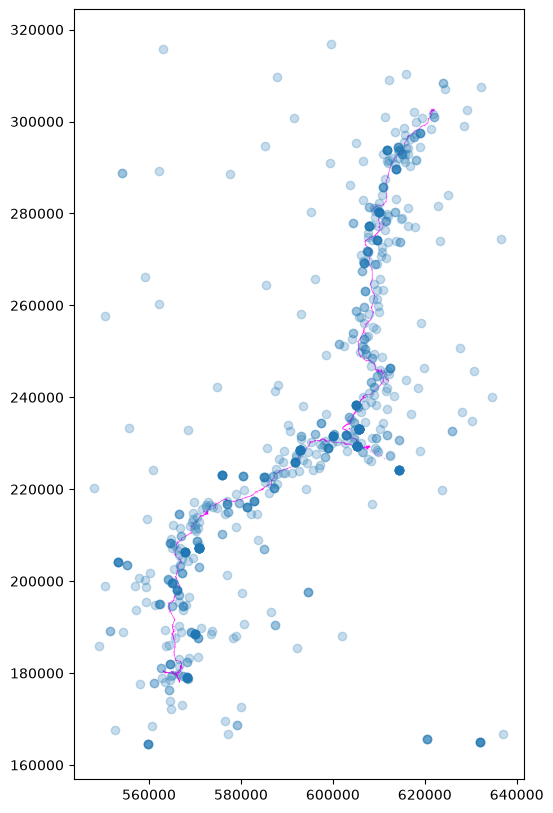

In [184]:
fig, ax = plt.subplots(figsize = (10, 10))
gdf_nt_route.plot(ax = ax, color = "magenta")
gdf_located_places.plot(ax = ax, alpha = 0.25)

In [ ]:
# Where the first word of a multiword phrase is matchable, it should go down as an additional match for that place. (Though ultimately we will only count one mention per representation.) => This is now done, and doubled the amount of places we succeeded in locating.
# There is still the option to use nominatim to locate more.
# There is the option to locate the pylons that are mentioned also.
# We might need to check for letters that have been copied and pasted as these do not necessarily represent genuine concern about all the places mentioned.